<a href="https://colab.research.google.com/github/HAX1122/breast-cancer-classification/blob/main/hatem_2337073_alwleed_2342305.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, silhouette_score
np.random.seed(42)

In [ ]:
data = load_wine()



X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)



print("Shape:", X.shape)
print("Classes:", y.unique())
print("Balance:\n", y.value_counts())
print("Missing count:", X.isnull().sum().sum())

Shape: (178, 13)
Classes: [0 1 2]
Balance:
 1    71
0    59
2    48
Name: count, dtype: int64
Missing count: 0


In [ ]:
X.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [ ]:
model = LogisticRegression(max_iter=5000, random_state=42)
model.fit(X_train_s, y_train)
y_pred = model.predict(X_test_s)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("Accuracy:", acc)
print("Macro F1:", f1)
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 0.9722222222222222
Macro F1: 0.9709618874773139

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36


Confusion Matrix:
 [[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]


In [ ]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train_s, y_train)
tree_acc = accuracy_score(y_test, tree_model.predict(X_test_s))

print("Tree Accuracy:", tree_acc)
print("Winner:", "Logistic Regression" if acc > tree_acc else "Decision Tree")

Tree Accuracy: 0.9444444444444444
Winner: Logistic Regression


In [ ]:
cv = cross_val_score(LogisticRegression(max_iter=5000, random_state=42), X_train_s, y_train, cv=5)
print("Mean CV:", cv.mean())
print("Std CV:", cv.std())

Mean CV: 0.9859605911330049
Std CV: 0.01719910369467594


In [ ]:
X_all_s = StandardScaler().fit_transform(X)


kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_all_s)
sil = silhouette_score(X_all_s, clusters)

print("Silhouette Score:", sil)
print("Inertia:", kmeans.inertia_)

Silhouette Score: 0.2848589191898987
Inertia: 1277.928488844643


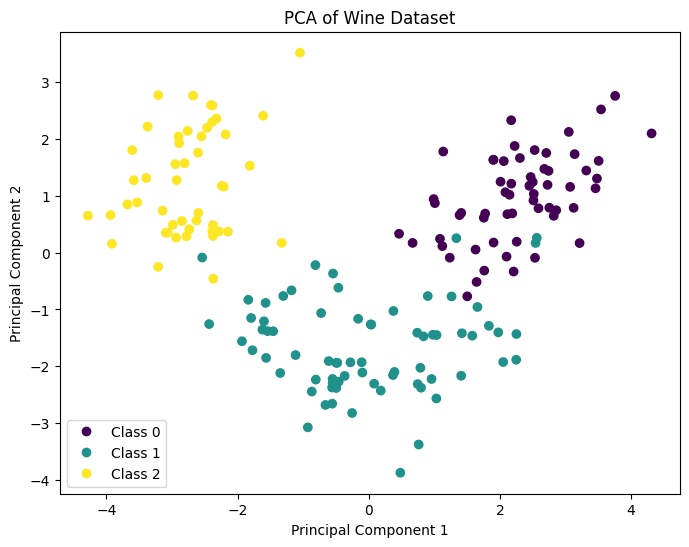

In [ ]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_all_s)
evr = pca.explained_variance_ratio_

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
plt.title("PCA of Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(handles=scatter.legend_elements()[0], labels=["Class 0", "Class 1", "Class 2"])
plt.show()